# MODEL: EfficientNetB0
TASK : Crop Pest and Disease Detection - End-to-End Pipeline
Paste each CELL block into a separate cell in your Jupyter Notebook.
Run cells in order from top to bottom.

---


### Digital Image Processing Concepts Used in This Model

In digital image processing (DIP) for agricultural automation, identifying crop pests and diseases requires analyzing spatial gradients, color channel distributions, and textural structures from digital pixel matrices. Biological pathogens induce localized foliar cellular degeneration, manifesting as chlorotic rings, necrotic lesions, powdery fungal sporulation, and irregular blights.

#### Why Crop Images Require Preprocessing
1. **Uncontrolled Outdoor Lighting:** Natural field illumination introduces solar glare, deep shadows, and color temperature shifts that distort raw pixel intensity distributions.
2. **Variable Capture Perspective:** Handheld and drone cameras capture leaves at diverse angles and distances, altering apparent symptom dimensions and orientation.
3. **Complex Agricultural Backgrounds:** Soil, dead organic mulch, and background foliage introduce non-target high-frequency spatial noise.
4. **Sensor Downsampling & Quantization:** Converting optical signals into digital matrices requires standardized spatial and radiometric normalization.

#### Spatial and Intensity Transformations in Training
- **Geometric Transformations:** Horizontal and vertical reflections, affine rotations ($\pm 90^\circ$), and zoom scaling enforce rotational and scale invariance.
- **Intensity Transformations:** Contrast stretching and brightness adjustments simulate varying daylight intensity without altering structural lesion morphology.

#### EfficientNetB0: Compound Scaling and Squeeze-and-Excitation Attention
Traditional architectures scale a single dimension (such as network depth in ResNet, or channel width in WideResNet). EfficientNet introduces **Compound Scaling**, uniformly scaling:
- **Network Depth ($d$):** Number of layers.
- **Network Width ($w$):** Channel capacity per layer.
- **Input Resolution ($r$):** Spatial dimensions of the processed image tensor.

EfficientNetB0 integrates **Mobile Inverted Bottleneck Convolutions (MBConv)** with **Squeeze-and-Excitation (SE) channel attention**. SE blocks explicitly model interdependencies between feature channels, dynamically recalibrating feature maps to amplify disease-indicative chromatic and textural patterns while dampening uninformative background noise.

#### End-to-End DIP & Classification Pipeline
$$\text{Input Image } (H \times W \times 3) \longrightarrow \text{Image Decoding \& Resizing } (224 \times 224) \longrightarrow \text{Data Augmentation } \longrightarrow \text{Internal Rescaling [0, 255] } \longrightarrow \text{MBConv + SE Feature Extraction } \longrightarrow \text{Global Pooling } \longrightarrow \text{Dense Classification}$$

> **Important Case Study Note:** This model performs **whole-image classification** (predicting the disease category for the entire tile) rather than explicit **semantic pixel segmentation** (which would delineate exact boundary contours for each diseased lesion).

### CELL 1 ── Install Dependencies


In [4]:
!pip install -q split-folders scikit-learn seaborn matplotlib tensorflow

### CELL 2 ── Imports


In [5]:
import os
import warnings
import splitfolders
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, callbacks
from tensorflow.keras.applications import EfficientNetB0
# NOTE: EfficientNetB0 does NOT need a separate preprocess_input — it handles
# scaling internally. Just pass raw [0,255] pixel values.
from sklearn.metrics import classification_report, confusion_matrix

warnings.filterwarnings("ignore")
print("TensorFlow:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.22.0-rc0
GPU Available: []


### CELL 3 ── Verify & Load Local Dataset  (70 / 15 / 15)


In [6]:
# ==============================================================================
# DATASET PATH CONFIGURATION (Local Dataset in this folder)
# ==============================================================================
# The dataset is stored locally in this project directory.
# - 'Dataset_Split': contains pre-split train (70%), val (15%), and test (15%) sets
# - 'dataset': contains the raw unsplit 22 disease/pest class folders

def resolve_path(folder_name):
    """Resolve local dataset folder path in the project workspace."""
    candidates = [
        folder_name,
        os.path.join(os.getcwd(), folder_name),
        os.path.join(os.path.dirname(os.path.abspath(__file__)) if "__file__" in locals() else ".", folder_name),
    ]
    for path in candidates:
        if os.path.exists(path):
            return path
    return folder_name

SPLIT_DIR = resolve_path("Dataset_Split")
RAW_DIR   = resolve_path("dataset")

if os.path.exists(SPLIT_DIR):
    print(f"[OK] Using local split dataset from: '{SPLIT_DIR}'")
elif os.path.exists(RAW_DIR):
    print(f"[NOTE] 'Dataset_Split' not found. Splitting local dataset from: '{RAW_DIR}' (70/15/15)...")
    splitfolders.ratio(RAW_DIR, output=SPLIT_DIR, seed=42, ratio=(0.70, 0.15, 0.15), group_prefix=None)
    print("[OK] Split complete.")
else:
    raise FileNotFoundError(
        f"Dataset not found in this folder! Looked for '{SPLIT_DIR}' and '{RAW_DIR}'. "
        "Please ensure the dataset folder is located in the project directory."
    )

TRAIN_DIR = os.path.join(SPLIT_DIR, "train")
VAL_DIR   = os.path.join(SPLIT_DIR, "val")
TEST_DIR  = os.path.join(SPLIT_DIR, "test")

print(f"  --> Train path : {TRAIN_DIR}")
print(f"  --> Val path   : {VAL_DIR}")
print(f"  --> Test path  : {TEST_DIR}")


[OK] Using local split dataset from: 'Dataset_Split'
  --> Train path : Dataset_Split\train
  --> Val path   : Dataset_Split\val
  --> Test path  : Dataset_Split\test


### DIP: Digital Image Representation, Decoding, and Spatial Resizing

#### Digital Color Image Representation
A digital color photograph is represented as a 3D numerical matrix of shape $(H \times W \times 3)$, where $H$ is the spatial height, $W$ is the spatial width, and 3 represents the primary color channels: **Red (R), Green (G), and Blue (B)**. Each pixel intensity is an 8-bit unsigned integer ($uint8$) with values spanning $[0, 255]$.

#### Image Decoding
Stored JPEG images are compressed using Discrete Cosine Transform (DCT) quantization. During input pipeline execution, TensorFlow decompresses raw binary bitstreams into uncompressed 3D arrays of numerical pixel intensities.

#### Image Resizing and Spatial Downsampling
Deep neural networks process data in batches, requiring fixed, standardized tensor dimensions ($B \times H \times W \times C$):
- **EfficientNetB0 Resolution:** Input images are standardized to **$224 \times 224$ pixels**.
- **Computational Trade-Off:** Resizing standardizes camera captures of varying resolutions into $224 \times 224 \times 3 = 150,528$ values, balancing computational throughput with structural fidelity.
- **Resolution Loss:** Downsampling high-resolution images can blur subtle early-stage fungal pustules or faint leaf miner tracks.
- **Aspect Ratio Distortion:** Direct bilinear downsampling to a square without padding may stretch non-square camera frames.

### CELL 4 ── Hyper-parameters & Data Loaders


In [7]:
BATCH_SIZE = 32
IMG_SIZE   = (224, 224)
EPOCHS     = 25
SEED       = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, seed=SEED, image_size=IMG_SIZE,
    batch_size=BATCH_SIZE, shuffle=True)

val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR, seed=SEED, image_size=IMG_SIZE,
    batch_size=BATCH_SIZE, shuffle=False)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR, seed=SEED, image_size=IMG_SIZE,
    batch_size=BATCH_SIZE, shuffle=False)

CLASS_NAMES = train_ds.class_names
NUM_CLASSES = len(CLASS_NAMES)
print(f"Classes ({NUM_CLASSES}): {CLASS_NAMES}")

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds   = val_ds.prefetch(AUTOTUNE)
test_ds  = test_ds.prefetch(AUTOTUNE)

Found 17568 files belonging to 22 classes.
Found 3761 files belonging to 22 classes.
Found 3795 files belonging to 22 classes.
Classes (22): ['Cashew anthracnose', 'Cashew gumosis', 'Cashew healthy', 'Cashew leaf miner', 'Cashew red rust', 'Cassava bacterial blight', 'Cassava brown spot', 'Cassava green mite', 'Cassava healthy', 'Cassava mosaic', 'Maize fall armyworm', 'Maize grasshoper', 'Maize healthy', 'Maize leaf beetle', 'Maize leaf blight', 'Maize leaf spot', 'Maize streak virus', 'Tomato healthy', 'Tomato leaf blight', 'Tomato leaf curl', 'Tomato septoria leaf spot', 'Tomato verticulium wilt']


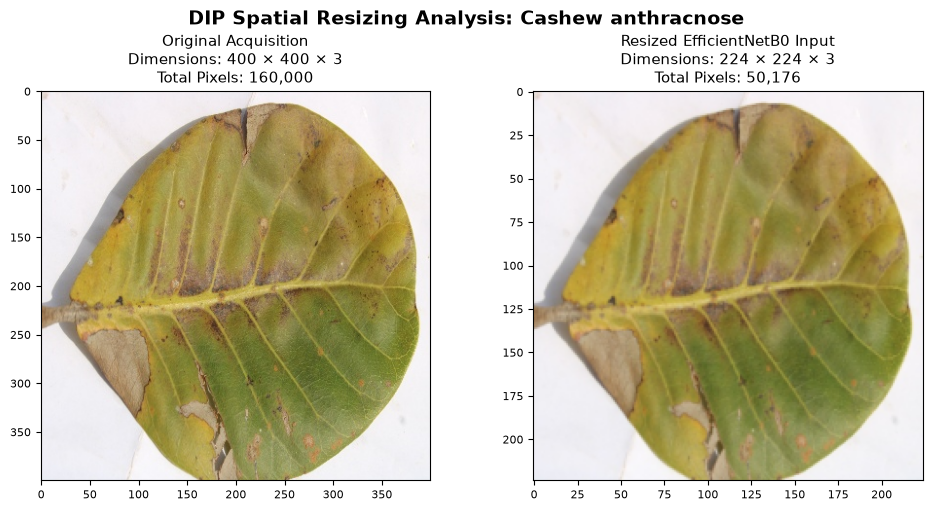

Spatial reduction ratio: 3.19x fewer pixels.


In [8]:
# DIP VISUALIZATION: Original Image vs. Resized Model Input (224x224)
import glob
from PIL import Image

sample_search = glob.glob(os.path.join(TRAIN_DIR, "*", "*.jpg"))
if sample_search:
    sample_file_path = sample_search[0]
    class_folder_name = os.path.basename(os.path.dirname(sample_file_path))
    
    orig_img = Image.open(sample_file_path)
    orig_w, orig_h = orig_img.size
    resized_img = orig_img.resize(IMG_SIZE, Image.BILINEAR)
    
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    fig.suptitle(f"DIP Spatial Resizing Analysis: {class_folder_name}", fontsize=14, fontweight="bold")
    
    axes[0].imshow(orig_img)
    axes[0].set_title(f"Original Acquisition\nDimensions: {orig_h} × {orig_w} × 3\nTotal Pixels: {orig_h * orig_w:,}", fontsize=11)
    axes[0].axis("on"); axes[0].tick_params(labelsize=8)
    
    axes[1].imshow(resized_img)
    axes[1].set_title(f"Resized EfficientNetB0 Input\nDimensions: {IMG_SIZE[1]} × {IMG_SIZE[0]} × 3\nTotal Pixels: {IMG_SIZE[0] * IMG_SIZE[1]:,}", fontsize=11)
    axes[1].axis("on"); axes[1].tick_params(labelsize=8)
    
    plt.tight_layout()
    plt.show()
    print(f"Spatial reduction ratio: {(orig_h * orig_w) / (IMG_SIZE[0] * IMG_SIZE[1]):.2f}x fewer pixels.")
else:
    print("No images found for resizing demonstration.")

### CELL 5 ── Explore: Sample Images


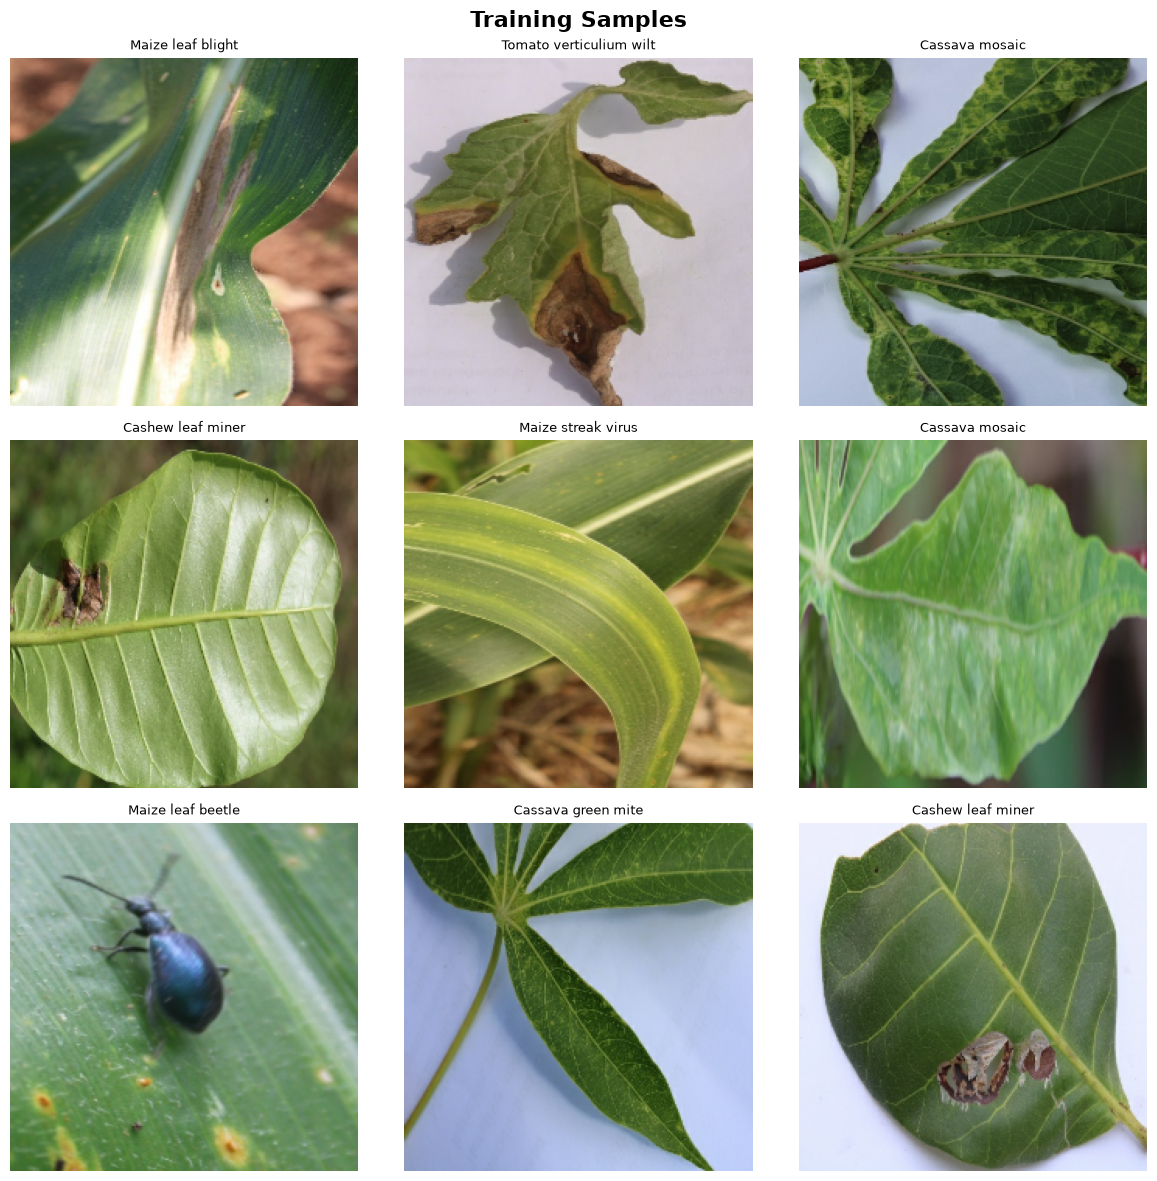

In [9]:
plt.figure(figsize=(12, 12))
plt.suptitle("Training Samples", fontsize=16, fontweight="bold")
for images, labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(CLASS_NAMES[labels[i]], fontsize=9)
        plt.axis("off")
plt.tight_layout(); plt.show()

### CELL 6 ── Class Distribution


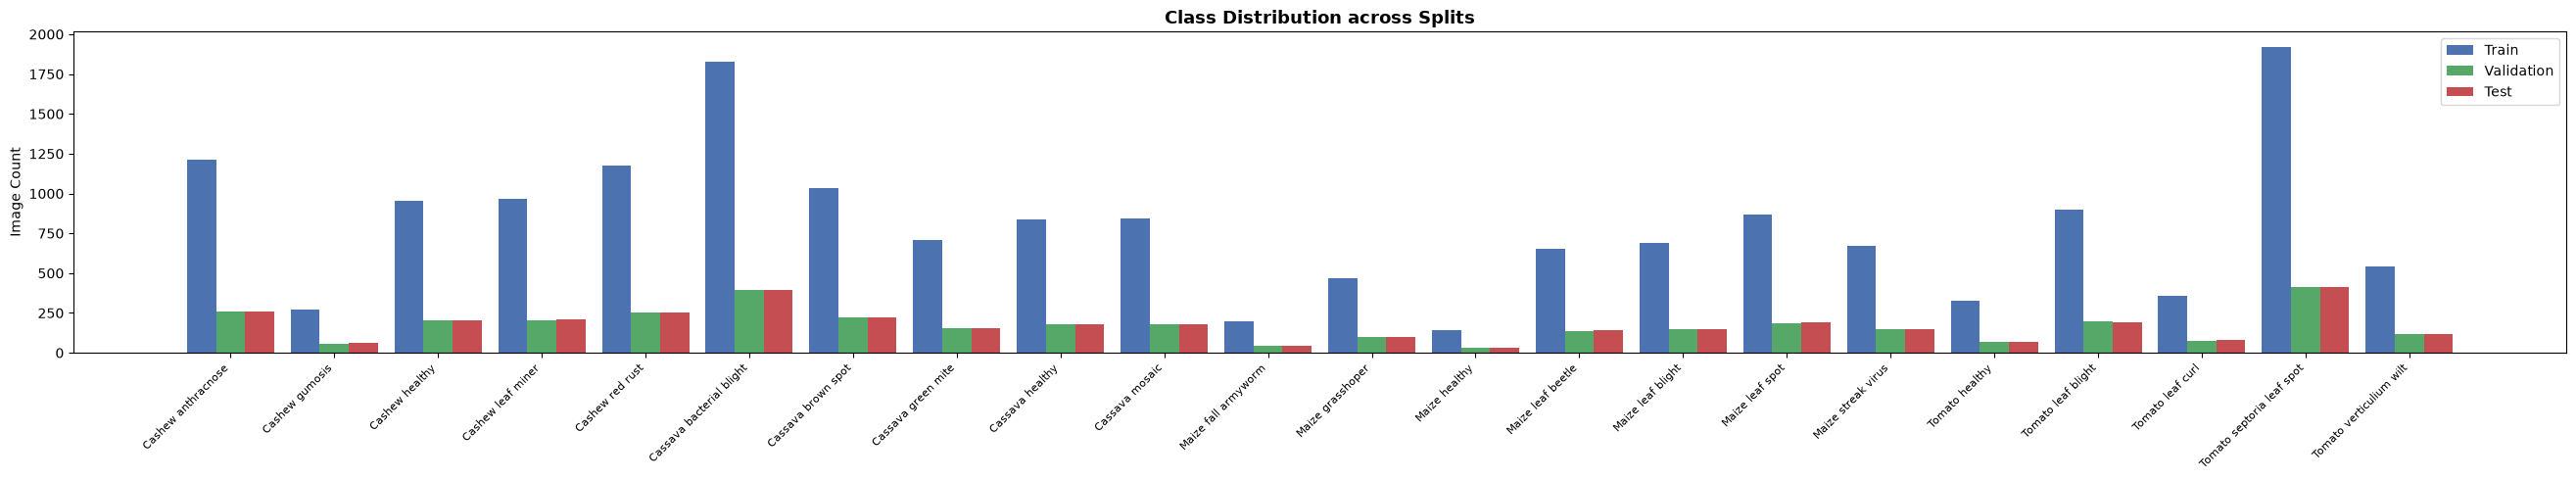

In [10]:
def count_classes(directory, class_names):
    return [len(os.listdir(os.path.join(directory, c))) for c in class_names]

train_counts = count_classes(TRAIN_DIR, CLASS_NAMES)
val_counts   = count_classes(VAL_DIR,   CLASS_NAMES)
test_counts  = count_classes(TEST_DIR,  CLASS_NAMES)

x = np.arange(NUM_CLASSES)
w = 0.28
fig, ax = plt.subplots(figsize=(max(12, NUM_CLASSES * 1.2), 5))
ax.bar(x - w, train_counts, w, label="Train",      color="#4C72B0")
ax.bar(x,     val_counts,   w, label="Validation",  color="#55A868")
ax.bar(x + w, test_counts,  w, label="Test",        color="#C44E52")
ax.set_xticks(x); ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right", fontsize=8)
ax.set_title("Class Distribution across Splits", fontsize=13, fontweight="bold")
ax.set_ylabel("Image Count"); ax.legend()
plt.tight_layout(); plt.show()

### DIP: Geometric and Intensity Transformations

Data augmentation applies digital image processing transformations to synthetic training images, expanding effective dataset variance and enforcing invariance to camera orientation and field illumination.

#### 1. Geometric Transformations (Spatial Coordinate Remapping)
Geometric transformations alter the spatial coordinates $(x, y)$ of image pixels via 2D spatial mapping functions $I'(x', y') = I(T_x(x, y), T_y(x, y))$:
- **Spatial Reflection (Flipping):** `RandomFlip("horizontal_and_vertical")` reflects pixels across horizontal ($y' = H - y$) and vertical ($x' = W - x$) axes. Foliar diseases possess no fixed gravitational orientation.
- **Rotation:** `RandomRotation(0.25)` applies 2D affine rotation. In Keras, a factor of **$0.25$ represents a fraction of $2\pi$**, meaning images are randomly rotated within $[-0.25 \times 360^\circ, +0.25 \times 360^\circ] = [-90^\circ, +90^\circ]$ (a full quarter turn), **not** 25 degrees.
- **Scaling (Zoom):** `RandomZoom(0.20)` scales coordinates by $\pm 20\%$, simulating variable camera working distances.

#### 2. Intensity Transformations (Radiometric Point Operations)
Intensity transformations modify pixel intensity values directly without altering spatial pixel geometry:
- **Contrast Adjustment:** `RandomContrast(0.15)` dynamically stretches or compresses the image dynamic range around its mean intensity: $I'(x,y) = \bar{I} + c \cdot (I(x,y) - \bar{I})$, simulating variable ambient daylight and cloud cover.
- **Brightness Adjustment:** `RandomBrightness(0.10)` shifts intensity levels additively: $I'(x,y) = I(x,y) + \delta$, simulating overexposure or deep canopy shading.

### CELL 7 ── Data Augmentation


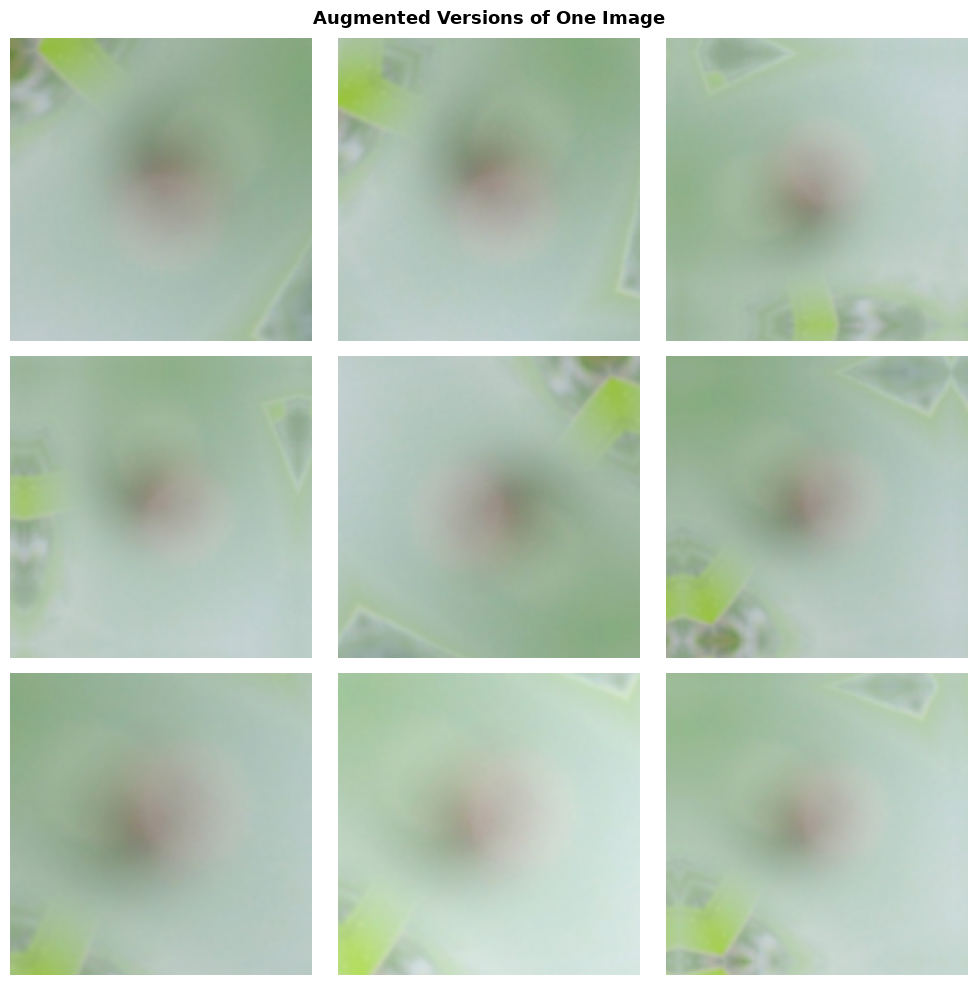

In [11]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.25),
    layers.RandomZoom(0.20),
    layers.RandomContrast(0.15),
    layers.RandomBrightness(0.10),
], name="augmentation")

for images, _ in train_ds.take(1):
    sample = images[0]
aug_samples = [data_augmentation(tf.expand_dims(sample, 0))[0] for _ in range(9)]

plt.figure(figsize=(10, 10))
plt.suptitle("Augmented Versions of One Image", fontsize=13, fontweight="bold")
for i, img in enumerate(aug_samples):
    plt.subplot(3, 3, i + 1)
    plt.imshow(img.numpy().astype("uint8")); plt.axis("off")
plt.tight_layout(); plt.show()

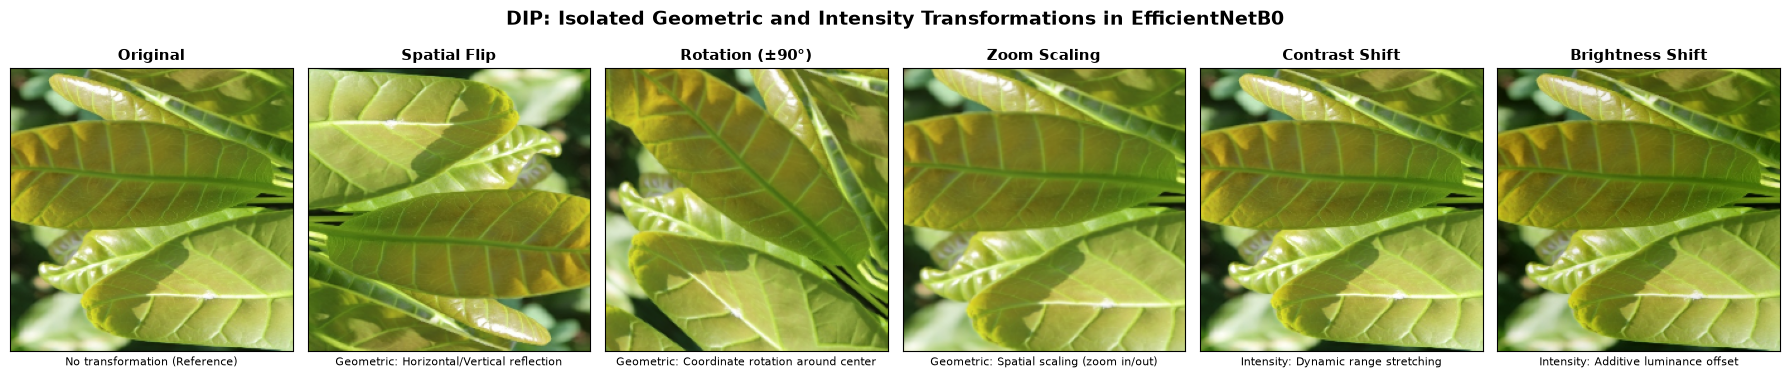

In [12]:
# DIP VISUALIZATION: Individual Geometric and Intensity Transformations Applied Separately
for images, _ in train_ds.take(1):
    base_sample = images[0]
    break

t_flip = layers.RandomFlip("horizontal_and_vertical", seed=42)
t_rot  = layers.RandomRotation(0.25, seed=42)            # +/- 90 degrees
t_zoom = layers.RandomZoom(0.20, seed=42)                # +/- 20% zoom
t_cont = layers.RandomContrast(0.15, seed=42)            # +/- 15% contrast
t_brit = layers.RandomBrightness(0.10, value_range=(0, 255), seed=42) # +/- 10% brightness

sample_tensor = tf.expand_dims(base_sample, 0)

transforms_list = [
    ("Original", base_sample.numpy().astype("uint8"), "No transformation (Reference)"),
    ("Spatial Flip", t_flip(sample_tensor)[0].numpy().astype("uint8"), "Geometric: Horizontal/Vertical reflection"),
    ("Rotation (±90°)", t_rot(sample_tensor)[0].numpy().astype("uint8"), "Geometric: Coordinate rotation around center"),
    ("Zoom Scaling", t_zoom(sample_tensor)[0].numpy().astype("uint8"), "Geometric: Spatial scaling (zoom in/out)"),
    ("Contrast Shift", t_cont(sample_tensor)[0].numpy().astype("uint8"), "Intensity: Dynamic range stretching"),
    ("Brightness Shift", t_brit(sample_tensor)[0].numpy().astype("uint8"), "Intensity: Additive luminance offset"),
]

fig, axes = plt.subplots(1, 6, figsize=(18, 3.8))
fig.suptitle("DIP: Isolated Geometric and Intensity Transformations in EfficientNetB0", fontsize=14, fontweight="bold")

for ax, (title, img_trans, desc) in zip(axes, transforms_list):
    ax.imshow(img_trans)
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_xlabel(desc, fontsize=8)
    ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()

### DIP: Convolutional Filtering and Hierarchical Feature Extraction

#### Mathematical Formulation of 2D Spatial Convolution
In discrete 2D digital image processing, spatial filtering correlates an input feature map $X$ with a 2D filter kernel $K$ of spatial dimensions $M \times N$:

$$Y(i, j) = (X * K)(i, j) = \sum_{m=-M/2}^{M/2} \sum_{n=-N/2}^{N/2} K(m, n) \cdot X(i + m, j + n)$$

#### EfficientNetB0: MBConv Blocks & Squeeze-and-Excitation Channel Attention
EfficientNetB0 builds upon inverted bottleneck residual blocks augmented with **Squeeze-and-Excitation (SE)** attention:
1. **Depthwise Spatial Convolution:** Computes spatial feature responses per channel using $3 \times 3$ or $5 \times 5$ depthwise kernels.
2. **Squeeze Step (Global Context Aggregation):** Global spatial average pooling aggregates feature map $U_c$ into a channel-wise statistic $z_c$:
   $$z_c = \mathbf{F}_{sq}(U_c) = \frac{1}{H \times W} \sum_{i=1}^H \sum_{j=1}^W U_c(i, j)$$
3. **Excitation Step (Adaptive Feature Recalibration):** A two-layer bottleneck fully-connected network with gating produces channel-specific scale weights:
   $$\mathbf{s} = \mathbf{F}_{ex}(\mathbf{z}, \mathbf{W}) = \sigma(\mathbf{W}_2 \cdot \text{ReLU}(\mathbf{W}_1 \cdot \mathbf{z}))$$
4. **Channel Scaling:** The original spatial feature map is scaled by the channel weight:
   $$\widetilde{X}_c = s_c \cdot U_c$$
   In crop disease detection, this dynamic channel weighting automatically boosts channels highlighting chlorotic yellowing or necrotic lesion edges while dampening irrelevant soil background channels.

---

### DIP: Pixel Intensity Preprocessing

| Model | Preprocessing Function | Expected Pixel Scale | Transformations Applied |
|---|---|---|---|
| **EfficientNetB0** | Built-in internal normalization | Raw $[0, 255]$ uint8/float32 | Internal rescaling and ImageNet standardization embedded inside Keras model |

#### Critical Preprocessing Note:
Unlike ResNet50 or MobileNetV2, **EfficientNet includes its own Rescaling and Normalization layers inside the base model architecture**.
Raw pixel tensors in the range $[0, 255]$ must be fed directly into the model without applying external `preprocess_input` or manual `/ 255.0` rescaling, avoiding double normalization.

### CELL 8 ── Build EfficientNetB0 Transfer Learning Model


In [13]:
base_model = EfficientNetB0(
    input_shape=IMG_SIZE + (3,),
    include_top=False,
    weights="imagenet",
)
base_model.trainable = False

# EfficientNet includes its own rescaling — pass raw pixels directly
inputs  = tf.keras.Input(shape=IMG_SIZE + (3,))
x       = data_augmentation(inputs)
x       = base_model(x, training=False)   # no preprocess_input needed
x       = layers.GlobalAveragePooling2D()(x)
x       = layers.BatchNormalization()(x)
x       = layers.Dropout(0.40)(x)
x       = layers.Dense(256, activation="relu",
                        kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x)
x       = layers.Dropout(0.30)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

model = tf.keras.Model(inputs, outputs, name="EfficientNetB0_CropDisease")
model.summary()

Model: "EfficientNetB0_CropDisease"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 22)             │         5,654 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,388,281 (16.74 MB)

 Trainable params: 336,150 (1.28 MB)

 Non-trainable params: 4,052,131 (15.46 MB)

### Digital Image Processing vs. Machine Learning in Model Training

- **Image Processing Operations:** Resizing to $224 \times 224$, geometric coordinate transforms (flips, rotations, zooms), internal pixel normalization, depthwise spatial convolutions, Squeeze-and-Excitation channel recalibration, and global average pooling.
- **Machine Learning Operations:** Categorical cross-entropy loss computation, error backpropagation, Adam optimizer weight updates, learning rate reduction on plateaus, transfer learning backbone freezing (Phase 1), and selective layer unfreezing (Phase 2 fine-tuning).

DIP structures the optical signals into informative spatial feature representations; ML discovers the optimal weighting parameters across those representations.

### CELL 9 ── Compile & Train Phase 1 (frozen backbone)


In [14]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

cb_early = callbacks.EarlyStopping(monitor="val_loss", patience=5,
                                   restore_best_weights=True, verbose=1)
cb_lr    = callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.4,
                                       patience=2, min_lr=1e-7, verbose=1)
cb_ckpt  = callbacks.ModelCheckpoint("best_efficientnetb0.keras", save_best_only=True,
                                      monitor="val_accuracy", verbose=1)

history = model.fit(
    train_ds, epochs=EPOCHS, validation_data=val_ds,
    callbacks=[cb_early, cb_lr, cb_ckpt], verbose=1)
print("Phase-1 training complete.")

Epoch 1/25


549/549 ━━━━━━━━━━━━━━━━━━━━ 0s 530ms/step - accuracy: 0.6347 - loss: 1.2350
Epoch 1: val_accuracy improved from None to 0.78064, saving model to best_efficientnetb0.keras

Epoch 1: finished saving model to best_efficientnetb0.keras
549/549 ━━━━━━━━━━━━━━━━━━━━ 375s 642ms/step - accuracy: 0.6347 - loss: 1.2350 - val_accuracy: 0.7806 - val_loss: 0.6765 - learning_rate: 0.0010
Epoch 2/25
549/549 ━━━━━━━━━━━━━━━━━━━━ 0s 537ms/step - accuracy: 0.7244 - loss: 0.8550
Epoch 2: val_accuracy improved from 0.78064 to 0.80165, saving model to best_efficientnetb0.keras

Epoch 2: finished saving model to best_efficientnetb0.keras
549/549 ━━━━━━━━━━━━━━━━━━━━ 351s 640ms/step - accuracy: 0.7244 - loss: 0.8550 - val_accuracy: 0.8016 - val_loss: 0.6129 - learning_rate: 0.0010
Epoch 3/25
549/549 ━━━━━━━━━━━━━━━━━━━━ 0s 537ms/step - accuracy: 0.7451 - loss: 0.7674
Epoch 3: val_accuracy improved from 0.80165 to 0.81282, saving model to best_efficientnetb0.keras

Epoch 3: finished saving model to best_effi

### CELL 10 ── Fine-Tuning Phase 2 (unfreeze last 20 layers)


In [16]:
base_model.trainable = True
for layer in base_model.layers[:-20]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

history_ft = model.fit(
    train_ds, epochs=10, validation_data=val_ds,
    callbacks=[cb_early, cb_lr, cb_ckpt], verbose=1)
print("Fine-tuning complete.")

for k in history.history:
    history.history[k] += history_ft.history.get(k, [])

Epoch 1/10
549/549 ━━━━━━━━━━━━━━━━━━━━ 0s 707ms/step - accuracy: 0.7372 - loss: 0.8313
Epoch 1: val_accuracy did not improve from 0.85642
549/549 ━━━━━━━━━━━━━━━━━━━━ 491s 835ms/step - accuracy: 0.7372 - loss: 0.8313 - val_accuracy: 0.8293 - val_loss: 0.5367 - learning_rate: 1.0000e-05
Epoch 2/10
549/549 ━━━━━━━━━━━━━━━━━━━━ 0s 682ms/step - accuracy: 0.7702 - loss: 0.7139
Epoch 2: val_accuracy did not improve from 0.85642
549/549 ━━━━━━━━━━━━━━━━━━━━ 430s 783ms/step - accuracy: 0.7702 - loss: 0.7139 - val_accuracy: 0.8373 - val_loss: 0.5142 - learning_rate: 1.0000e-05
Epoch 3/10
549/549 ━━━━━━━━━━━━━━━━━━━━ 0s 715ms/step - accuracy: 0.7853 - loss: 0.6696
Epoch 3: val_accuracy did not improve from 0.85642
549/549 ━━━━━━━━━━━━━━━━━━━━ 456s 830ms/step - accuracy: 0.7853 - loss: 0.6696 - val_accuracy: 0.8402 - val_loss: 0.5007 - learning_rate: 1.0000e-05
Epoch 4/10
549/549 ━━━━━━━━━━━━━━━━━━━━ 0s 720ms/step - accuracy: 0.7949 - loss: 0.6296
Epoch 4: val_accuracy did not improve from 0.856

### CELL 11 ── Training Curves

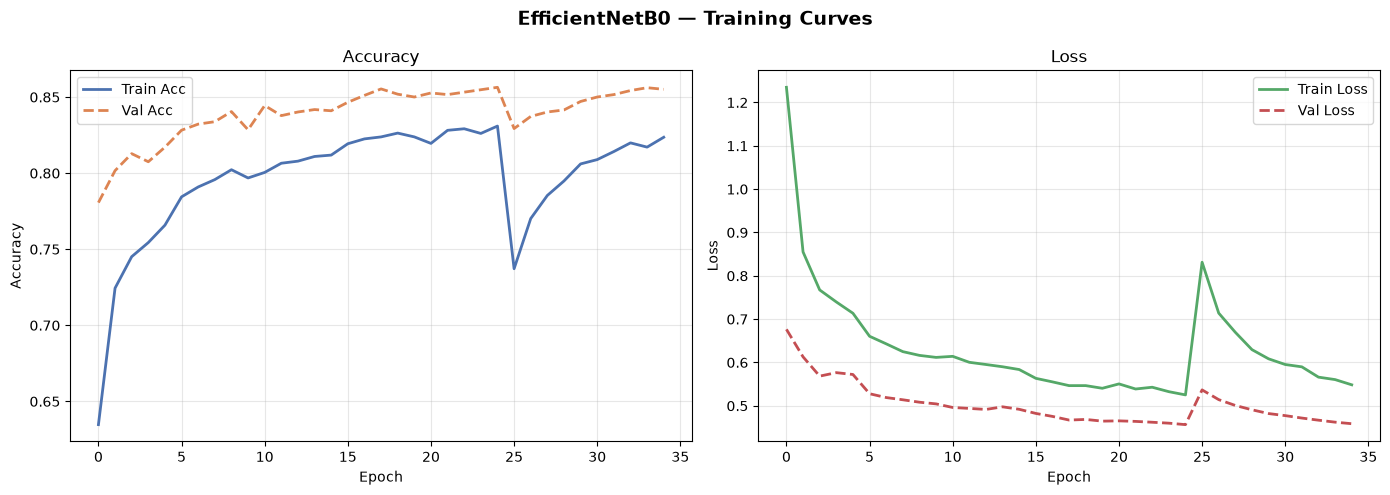

In [17]:
acc      = history.history["accuracy"]
val_acc  = history.history["val_accuracy"]
loss     = history.history["loss"]
val_loss = history.history["val_loss"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("EfficientNetB0 — Training Curves", fontsize=14, fontweight="bold")

axes[0].plot(acc,     label="Train Acc",  linewidth=2, color="#4C72B0")
axes[0].plot(val_acc, label="Val Acc",    linewidth=2, color="#DD8452", linestyle="--")
axes[0].set_title("Accuracy"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Accuracy")
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(loss,     label="Train Loss", linewidth=2, color="#55A868")
axes[1].plot(val_loss, label="Val Loss",   linewidth=2, color="#C44E52", linestyle="--")
axes[1].set_title("Loss"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Loss")
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout(); plt.show()

### CELL 12 ── Evaluate on Test Set


In [18]:
model.load_weights("best_efficientnetb0.keras")
test_loss, test_acc = model.evaluate(test_ds, verbose=1)
print(f"\nTest Accuracy : {test_acc  * 100:.2f}%")
print(f"Test Loss     : {test_loss:.4f}")

119/119 ━━━━━━━━━━━━━━━━━━━━ 56s 466ms/step - accuracy: 0.8577 - loss: 0.4471

Test Accuracy : 85.77%
Test Loss     : 0.4471


### CELL 13 ── Confusion Matrix & Classification Report



Classification Report:
                           precision    recall  f1-score   support

       Cashew anthracnose     0.9300    0.8692    0.8986       260
           Cashew gumosis     0.9677    1.0000    0.9836        60
           Cashew healthy     0.9444    0.9903    0.9668       206
        Cashew leaf miner     0.9167    0.9519    0.9340       208
          Cashew red rust     0.9882    0.9921    0.9901       253
 Cassava bacterial blight     0.8821    0.9135    0.8975       393
       Cassava brown spot     0.8879    0.8520    0.8696       223
       Cassava green mite     0.8720    0.9346    0.9022       153
          Cassava healthy     0.9565    0.9778    0.9670       180
           Cassava mosaic     0.9877    0.8846    0.9333       182
      Maize fall armyworm     0.9500    0.8636    0.9048        44
         Maize grasshoper     0.9600    0.9412    0.9505       102
            Maize healthy     0.6667    0.9375    0.7792        32
        Maize leaf beetle     0.9396 

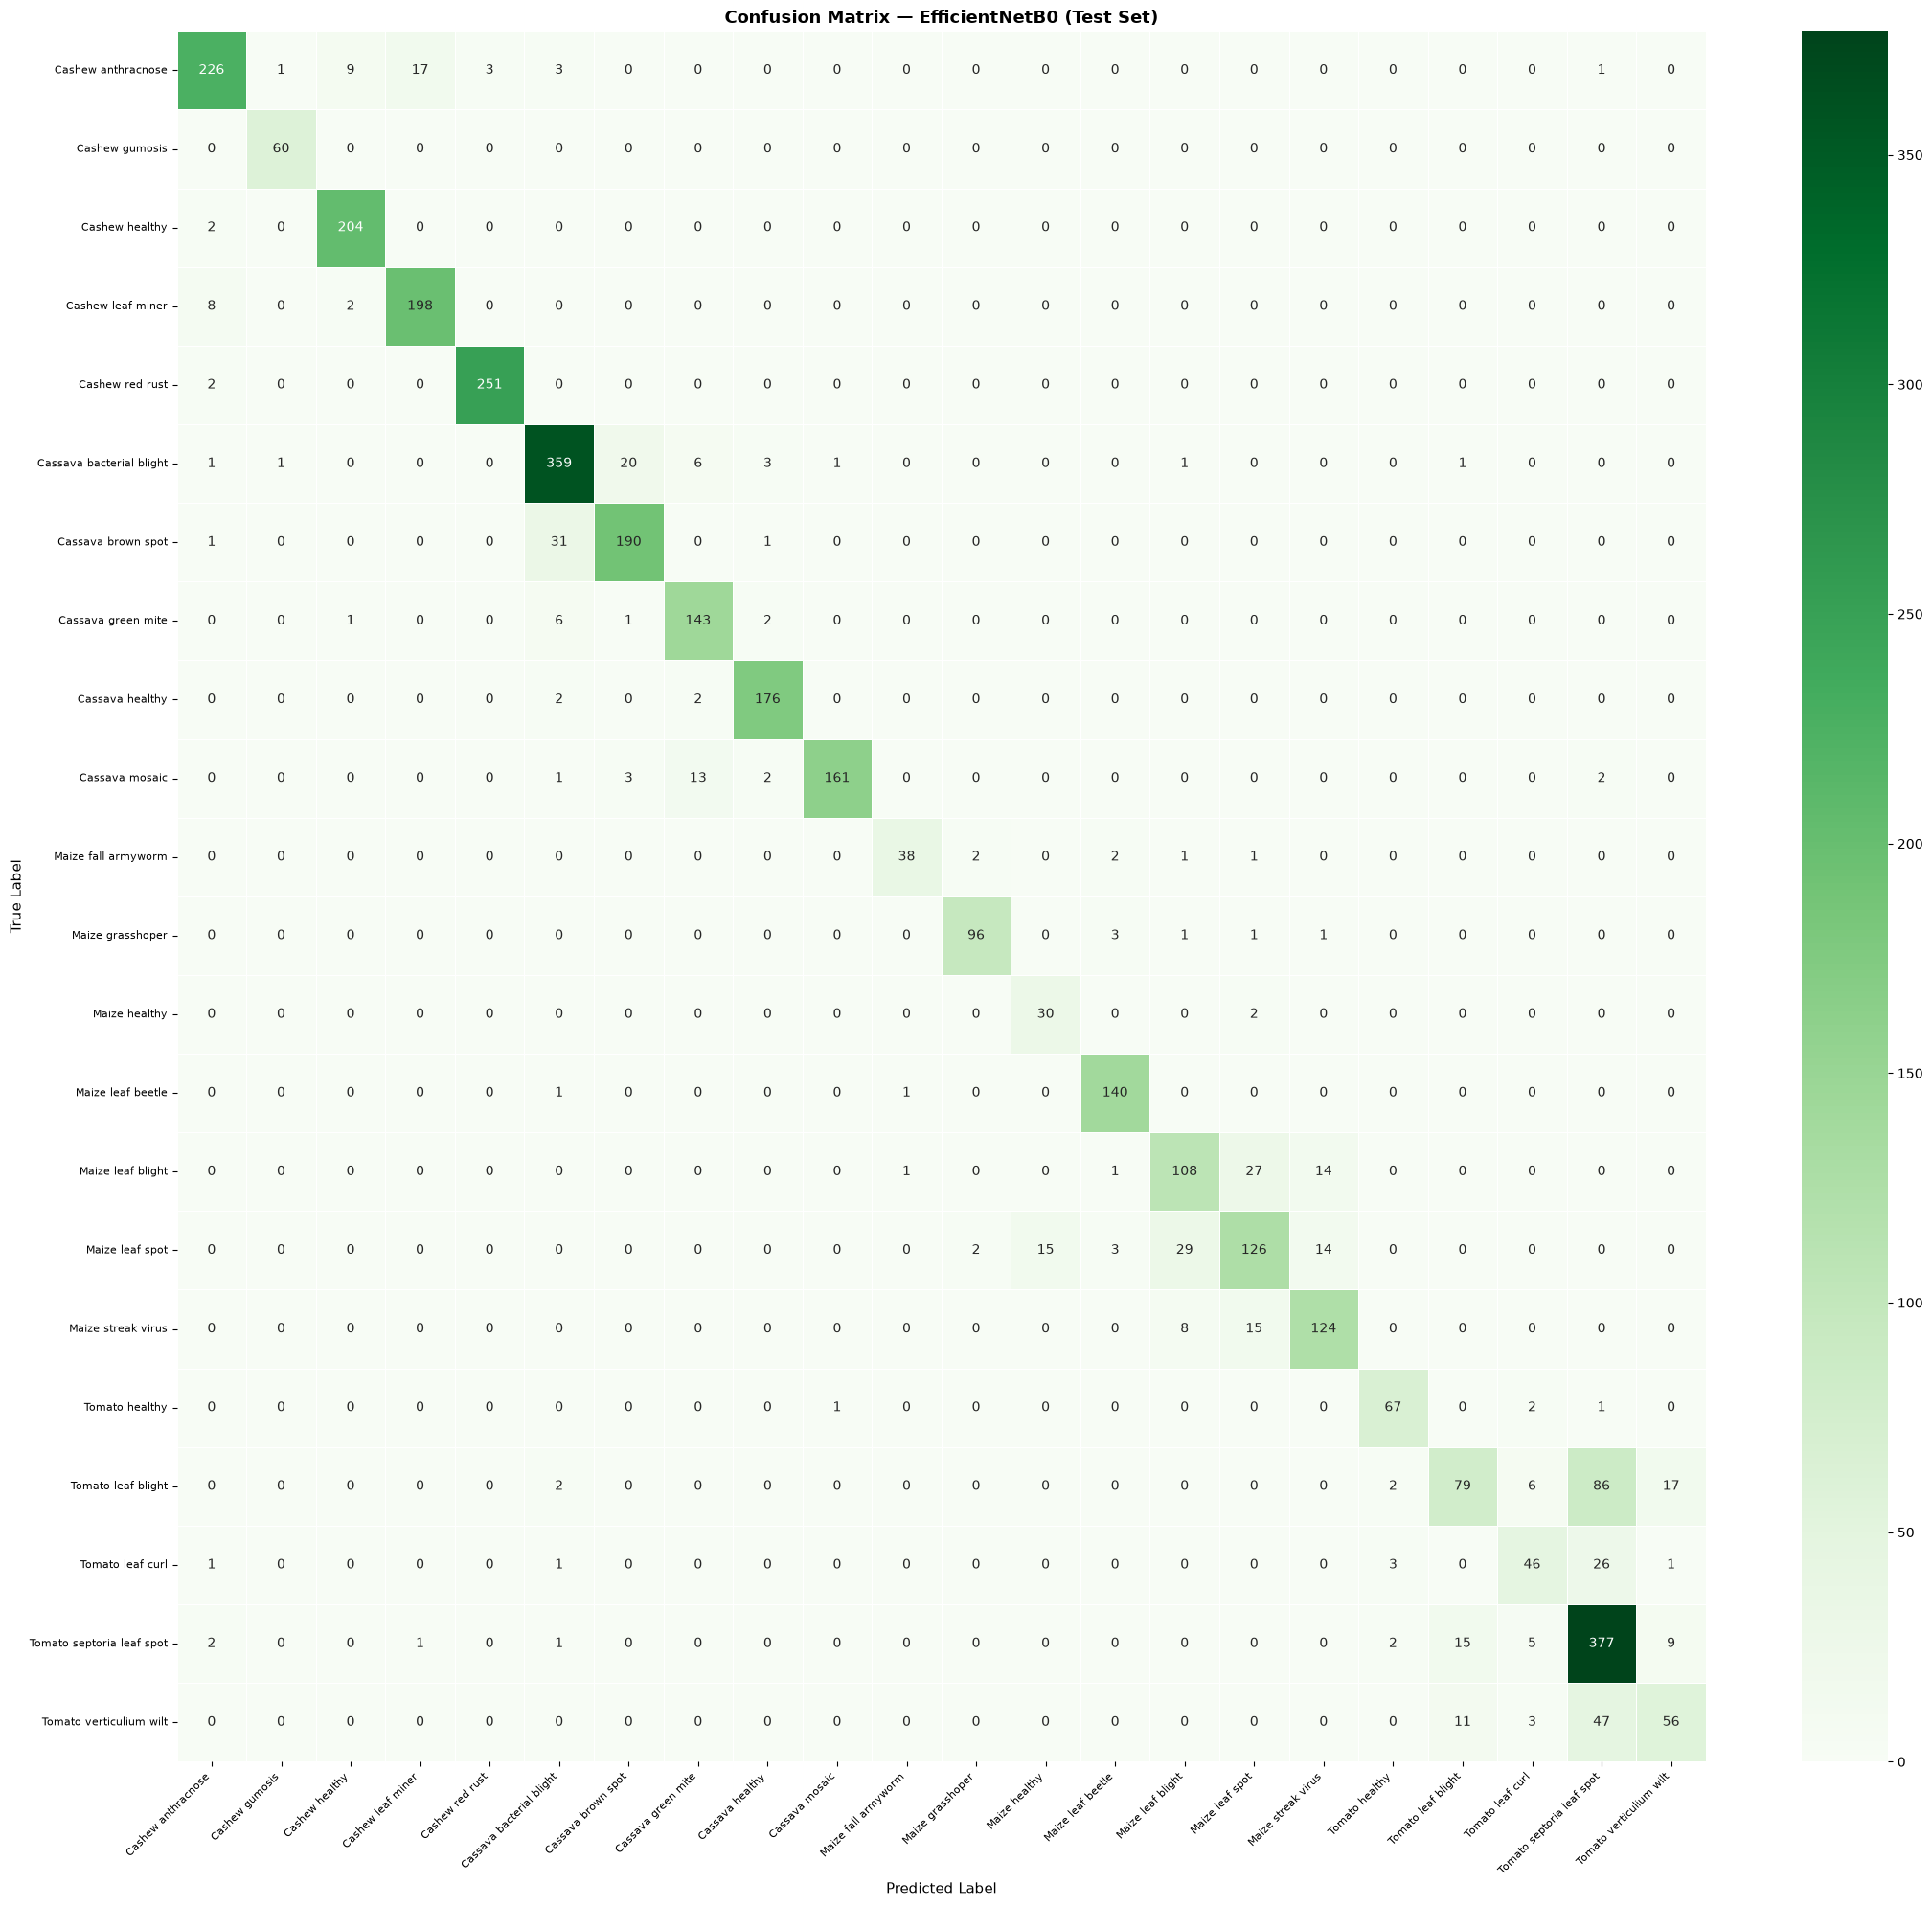

In [19]:
y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_prob = model.predict(test_ds, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(max(12, NUM_CLASSES), max(10, NUM_CLASSES - 2)))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, linewidths=0.5)
plt.title("Confusion Matrix — EfficientNetB0 (Test Set)", fontsize=13, fontweight="bold")
plt.xlabel("Predicted Label", fontsize=11); plt.ylabel("True Label", fontsize=11)
plt.xticks(rotation=45, ha="right", fontsize=8); plt.yticks(fontsize=8)
plt.tight_layout(); plt.show()

### CELL 14 ── Per-Class Accuracy Bar Chart


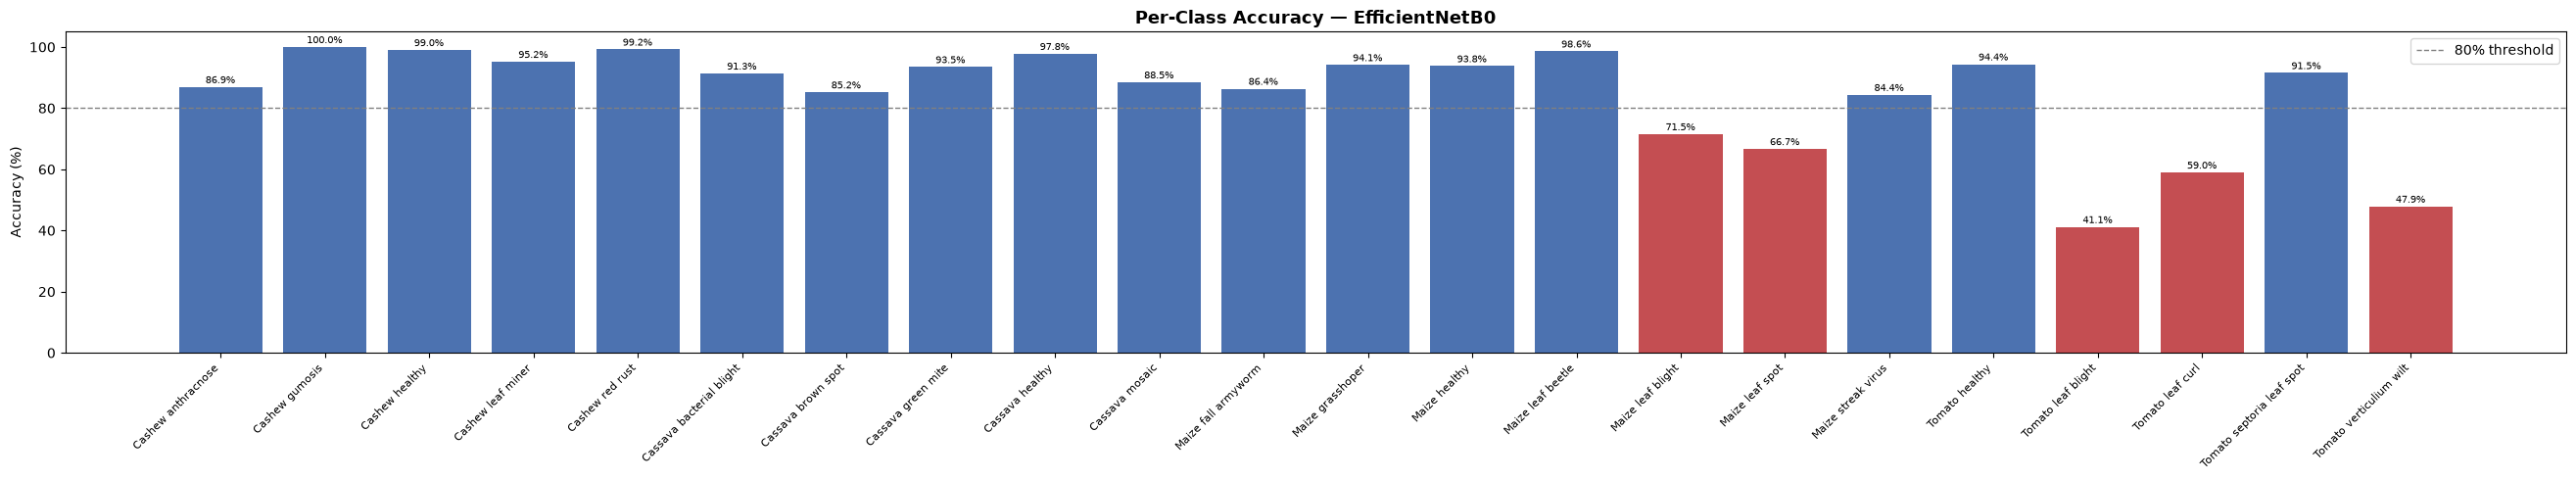

In [20]:
per_class_acc = cm.diagonal() / cm.sum(axis=1)

plt.figure(figsize=(max(12, NUM_CLASSES * 1.2), 5))
colors = ["#4C72B0" if a >= 0.8 else "#C44E52" for a in per_class_acc]
bars = plt.bar(CLASS_NAMES, per_class_acc * 100, color=colors)
plt.axhline(y=80, color="grey", linestyle="--", linewidth=1, label="80% threshold")
plt.xticks(rotation=45, ha="right", fontsize=8)
plt.ylabel("Accuracy (%)"); plt.title("Per-Class Accuracy — EfficientNetB0", fontsize=13, fontweight="bold")
plt.legend()
for bar, acc_val in zip(bars, per_class_acc):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
             f"{acc_val*100:.1f}%", ha="center", va="bottom", fontsize=7)
plt.tight_layout(); plt.show()

### CELL 15 ── Sample Predictions Grid (Green = Correct, Red = Wrong)


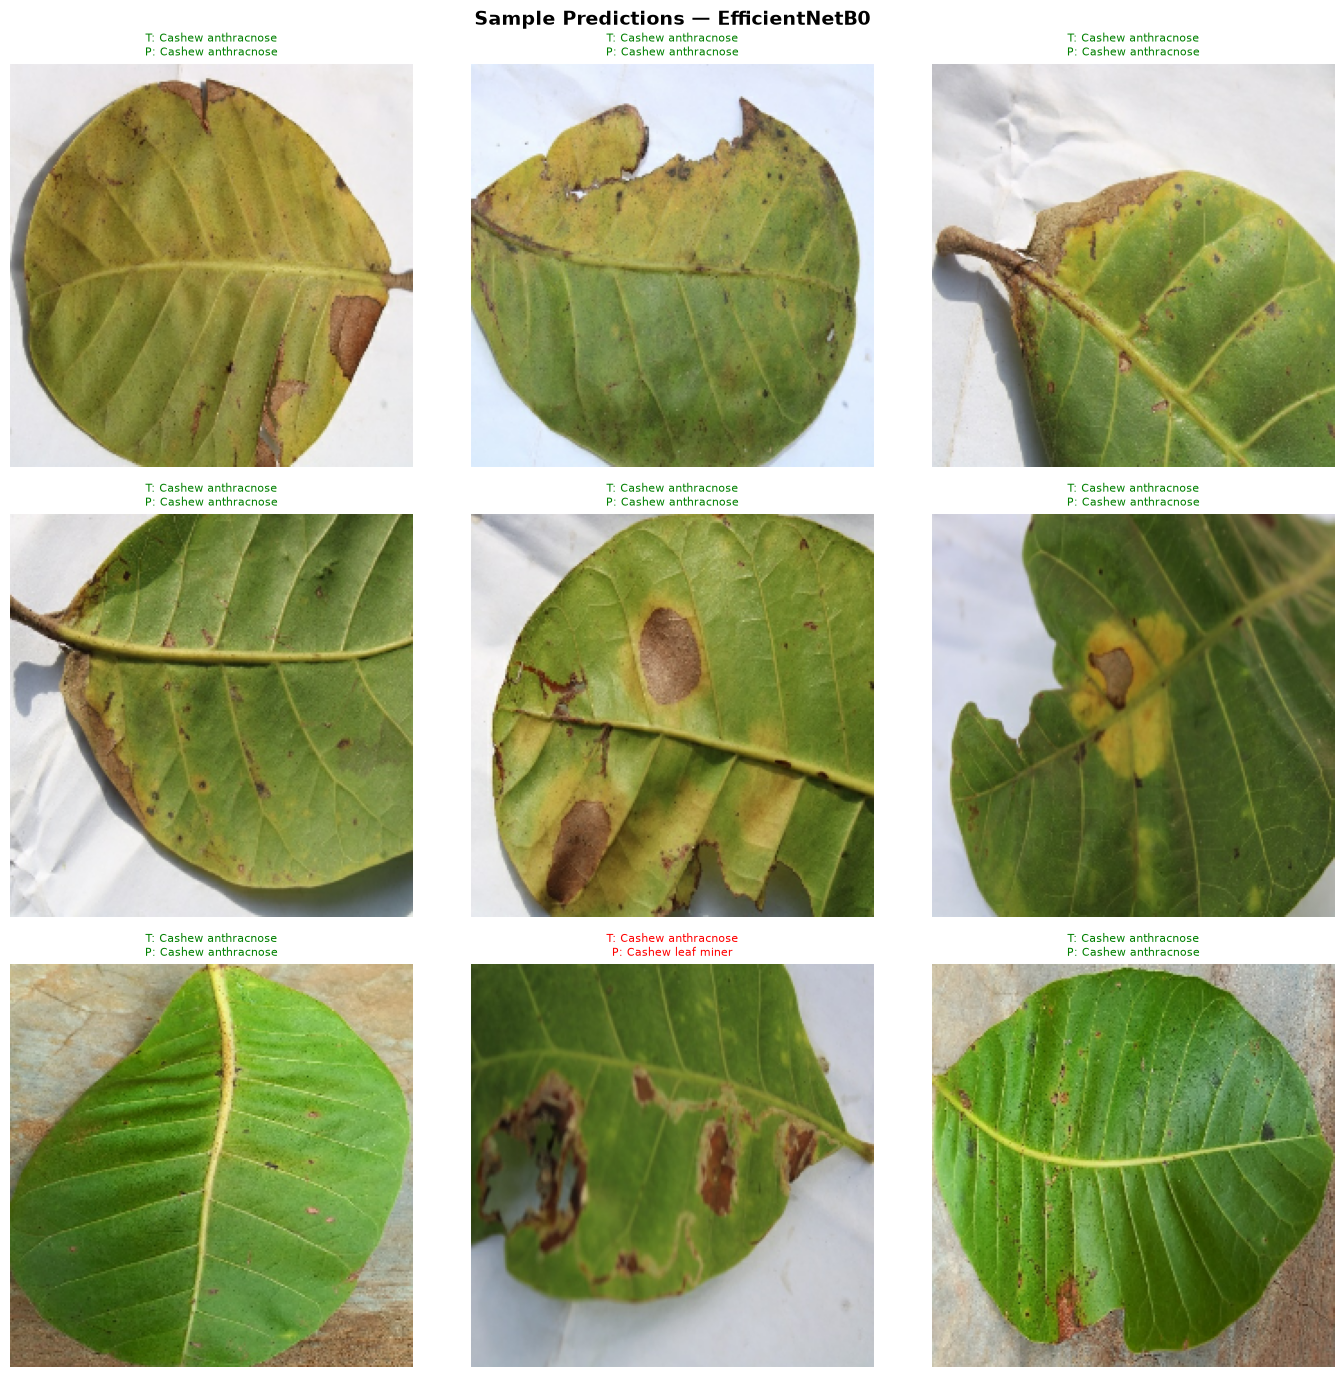

In [21]:
plt.figure(figsize=(14, 14))
plt.suptitle("Sample Predictions — EfficientNetB0", fontsize=14, fontweight="bold")
for images, labels in test_ds.take(1):
    preds = np.argmax(model.predict(images, verbose=0), axis=1)
    for i in range(min(9, len(images))):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        true_lbl = CLASS_NAMES[labels[i]]
        pred_lbl = CLASS_NAMES[preds[i]]
        colour   = "green" if true_lbl == pred_lbl else "red"
        plt.title(f"T: {true_lbl}\nP: {pred_lbl}", color=colour, fontsize=8)
        plt.axis("off")
plt.tight_layout(); plt.show()

### Interpretation of Image-Based Classification Results

In evaluating the sample prediction grid and confusion matrix from a digital image processing perspective:

1. **Visual Cues Leveraged by the Classifier:**
   - **Chromatic Discoloration:** Chlorotic margins and dark necrotic lesions serve as primary chromatic markers.
   - **Spatial Texture:** Powdery mildew, serpentine leaf miner tracks, and fungal spots provide distinct spatial frequency signatures.
2. **Sources of Inter-Class Confusion:**
   - **Morphological Similarity:** Early blight and leaf spots produce similar circular necrotic lesions.
   - **Environmental Artifacts:** Harsh daylight glares and deep foliage shadows can distort color and contrast.
   - **Complex Backgrounds:** Soil backgrounds and overlapping non-target vegetation introduce spurious edge responses.
3. **Academic Clarification on Evaluation vs. DIP:**
   - A **confusion matrix** evaluates categorical classification performance, not digital image processing.
   - A **whole-image classification label** indicates the diagnosis of the overall image tile; it does **not** generate pixel-level lesion boundary masks.
   - **Activation maps** show filter responses across spatial receptive fields; they do **not** constitute semantic segmentation masks.

### CELL 16 ── Save Final Model


In [15]:
model.save("EfficientNetB0_Crop_Disease_Final.keras")
print("Model saved →  EfficientNetB0_Crop_Disease_Final.keras")

Model saved →  EfficientNetB0_Crop_Disease_Final.keras


### Digital Image Processing Summary and Case Study Findings

#### 1. Input Image Representation and Dimensions
EfficientNetB0 processes standardized $224 \times 224 \times 3$ RGB digital images ($150,528$ pixel intensity values), decoded from JPEG files into numerical arrays.

#### 2. Image Transformations Applied
- **Geometric Transformations:** Horizontal and vertical reflections, affine rotation ($\pm 90^\circ$), and zoom scaling ($\pm 20\%$) enforce rotational and scale invariance against camera positioning.
- **Intensity Transformations:** Contrast adjustment ($\pm 15\%$) and brightness shifts ($\pm 10\%$) simulate changing sunlight and exposure levels.

#### 3. Pixel Intensity Preprocessing
EfficientNetB0 incorporates internal rescaling layers directly within its computation graph. Raw $[0, 255]$ pixel values are supplied without external normalization, preventing double rescaling.

#### 4. Convolutional Feature Extraction
EfficientNetB0 utilizes compound-scaled Mobile Inverted Bottleneck (MBConv) blocks coupled with Squeeze-and-Excitation (SE) channel attention. The SE mechanism dynamically recalibrates feature maps, directing attention to disease-relevant chromatic and textural patterns.

#### 5. Relevance to Crop Disease Identification
The compound scaling and channel attention mechanisms provide an optimal balance between parameter efficiency and discriminative representation, allowing the model to distinguish closely related foliar diseases.

#### 6. Limitations of the Image Processing Approach
- **No Explicit Lesion Segmentation:** Categorizes whole image tiles rather than segmenting individual lesion perimeters.
- **Downsampling:** Bilinear downsampling to $224 \times 224$ can suppress very fine micro-lesions.
- **Background Interference:** In the absence of explicit background masking, complex soil and weed textures can influence predictions.